# Экзамен: предсказания для Контеста

В этом ноутбуке запускали выбранную модель на экзаменационных фото и собирали файл для Контеста.

Модель та же, что и победила на нашем golden set: Qwen3-VL-2B-Instruct со строгим промптом (F1@0.5 = 0.880).
Настройки не меняли: float16, фото уменьшаем до 1024 px, порог и удаление дублей не используем.

Как запустить:
1. В Colab выбрать видеокарту: "Среда выполнения" → "Сменить среду выполнения" → T4 GPU
2. Загрузить в Colab файл `dataset.jsonl` от преподавателя (значок папки слева)
3. Нажать "Среда выполнения" → "Выполнить все". Займет примерно 20 минут
4. Готовый `exam_predictions.jsonl` отправить в Контест, компилятор `(make) python-handbook`

Ответы модели руками не исправляем, в Контест идет ровно то, что она выдала

## 1. Фото
Скачиваем 400 фото по ссылкам из dataset.jsonl и проверяем, что каждое открывается

In [ ]:
# Экзаменационный датасет: скачиваю фото по ссылкам
import json, os, requests
from PIL import Image

exam = [json.loads(line) for line in open("dataset.jsonl") if line.strip()]
print("фото в датасете:", len(exam))

os.makedirs("exam_images", exist_ok=True)
bad = []
for rec in exam:
    path = f"exam_images/{rec['photo_id']}.jpg"
    for attempt in range(3):
        try:
            if not os.path.exists(path):
                r = requests.get(rec["photo_url"], timeout=60)
                r.raise_for_status()
                open(path, "wb").write(r.content)
            Image.open(path).verify()          # проверяем, что файл открывается как картинка
            break
        except Exception as e:
            if os.path.exists(path):
                os.remove(path)
            if attempt == 2:
                bad.append((rec["photo_id"], str(e)))

print("скачано:", len(os.listdir("exam_images")), "| не скачались:", bad)

фото в датасете: 400
скачано: 400 | не скачались: []


## 2. Модель
Та же модель, версия весов и промпт, что выбрали по лидерборду ранее

In [ ]:
# Версия весов и те же настройки, что при выборе
import torch, re
from transformers import AutoModelForImageTextToText, AutoProcessor

QWEN = "Qwen/Qwen3-VL-2B-Instruct"
QWEN_REV = "89644892e4d85e24eaac8bacfd4f463576704203" # зафиксированная версия весов

model = AutoModelForImageTextToText.from_pretrained(QWEN, revision=QWEN_REV, dtype=torch.float16).to("cuda")
processor = AutoProcessor.from_pretrained(QWEN, revision=QWEN_REV)

PROMPT = ("Find every adult butterfly in the image. Give each butterfly its own tight box around "
          "the visible wings, body and antennae; if butterflies overlap, still box each one separately. "
          "Do NOT box moths, caterpillars, pupae, other insects, shadows or flowers. "
          "Output JSON only: [{\"bbox_2d\": [x1, y1, x2, y2], \"label\": \"butterfly\"}]. "
          "If there is no adult butterfly, output [].")


def ask_qwen(path):
    # показываем модели фото и промпт, получаем ответ текстом
    img = Image.open(path).convert("RGB")
    img.thumbnail((1024, 1024)) # большие фото уменьшаем
    messages = [{"role": "user", "content": [
        {"type": "image", "image": img},
        {"type": "text", "text": PROMPT},
    ]}]
    inputs = processor.apply_chat_template(messages, tokenize=True, add_generation_prompt=True,
                                           return_dict=True, return_tensors="pt").to("cuda")
    out = model.generate(**inputs, max_new_tokens=512, do_sample=False)   # без случайности
    answer = out[:, inputs["input_ids"].shape[1]:]    # берем только новый текст, без промпта
    return processor.batch_decode(answer, skip_special_tokens=True)[0]


def to_fraction(c):
    # Qwen пишет координаты от 0 до 1000, нам нужны доли от 0 до 1
    return min(max(c / 1000, 0), 1)


BBOX = r'"bbox_2d"\s*:\s*\[([^\]]+)\]'                # ищет в тексте "bbox_2d": [числа]

def parse_boxes(text):
    # достаем рамки из ответа; работает и если ответ оборвался на середине
    boxes = []
    for numbers in re.findall(BBOX, text):
        coords = [float(x) for x in numbers.split(",")]
        if len(coords) != 4:
            continue
        x1, y1, x2, y2 = coords
        left, right = sorted([to_fraction(x1), to_fraction(x2)])
        top, bottom = sorted([to_fraction(y1), to_fraction(y2)])
        if right > left and bottom > top:
            boxes.append({"left": left, "top": top, "width": right - left, "height": bottom - top})
    return boxes


def qwen_find(path):
    text = ask_qwen(path)
    return parse_boxes(text), text

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

## 3. Прогон
Если на каком-то фото ошибка, попробуем еще раз. Ошибки пишем в журнал, пустой ответ вместо ошибки не подставляем

In [ ]:
# 3. Прогон на всех 400 фото (около 20 минут)
from tqdm.auto import tqdm

result, raw, log = {}, {}, []
for rec in tqdm(exam):
    pid = rec["photo_id"]
    if pid in result:
        continue
    for attempt in range(3):
        try:
            result[pid], raw[pid] = qwen_find(f"exam_images/{pid}.jpg")
            break
        except Exception as e:
            log.append({"photo_id": pid, "attempt": attempt + 1, "error": str(e)})
            torch.cuda.empty_cache()

missing = [rec["photo_id"] for rec in exam if rec["photo_id"] not in result]
print("обработано:", len(result), "из", len(exam), "| попыток с ошибкой:", len(log), "| не получилось:", missing)
# если missing не пустой: просто запустить этот блок ещё раз: готовые фото пропускаются

  0%|          | 0/400 [00:00<?, ?it/s]

обработано: 400 из 400 | попыток с ошибкой: 0 | не получилось: []


## 4. Файл для Контеста
Собираем ответ, сохраняя сырые ответы модели и журнал ошибок и проверяем необходимый формат

In [ ]:
# собираю файл
with open("exam_predictions.jsonl", "w", encoding="utf-8") as f:
    for rec in exam:
        pid = rec["photo_id"]
        boxes = [{k: round(v, 6) for k, v in b.items()} for b in result[pid]]
        f.write(json.dumps({"photo_id": pid, "boxes": boxes, "error": None}) + "\n")

# сохраняю ответы модели, журнал ошибок
with open("exam_raw_answers.jsonl", "w", encoding="utf-8") as f:
    for rec in exam:
        f.write(json.dumps({"photo_id": rec["photo_id"], "raw_text": raw[rec["photo_id"]]}, ensure_ascii=False) + "\n")
with open("exam_errors_log.jsonl", "w", encoding="utf-8") as f:
    for r in log:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

# проверяю по правилам Контеста
rows = [json.loads(line) for line in open("exam_predictions.jsonl")]
ids = [r["photo_id"] for r in rows]
dataset_ids = [rec["photo_id"] for rec in exam]

bad_fields = 0
bad_boxes = 0
for r in rows:
    if set(r.keys()) != {"photo_id", "boxes", "error"}:
        bad_fields += 1
    for b in r["boxes"]:
        inside = b["left"] >= 0 and b["top"] >= 0 and b["left"] + b["width"] <= 1 and b["top"] + b["height"] <= 1
        if not inside or b["width"] <= 0 or b["height"] <= 0:
            bad_boxes += 1

print("строк в файле:", len(rows))
print("ID совпадают с датасетом:", sorted(ids) == sorted(dataset_ids))
print("повторов ID:", len(ids) - len(set(ids)))
print("строк с лишними полями:", bad_fields)
print("рамок вне кадра:", bad_boxes)
print("размер:", round(os.path.getsize("exam_predictions.jsonl") / 1024, 1), "КБ (лимит 5120 КБ)")

строк в файле: 400
ID совпадают с датасетом: True
повторов ID: 0
строк с лишними полями: 0
рамок вне кадра: 0
размер: 32.5 КБ (лимит 5120 КБ)


## Проверка результата
Ничего не меняю, только смотрю ответы модели: распределение рамок и картинки

фото без бабочек: 182 | с одной: 212 | с 2+: 6 | всего рамок: 224


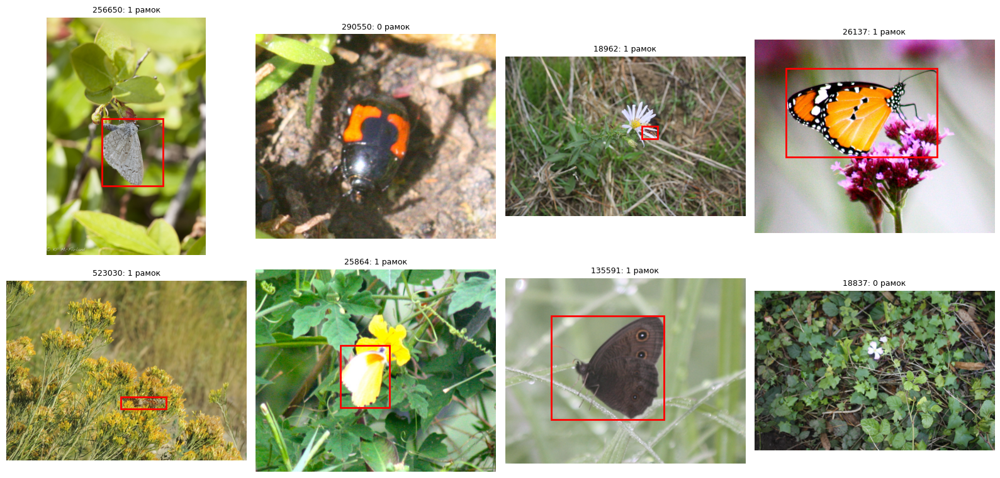

In [ ]:
import random, matplotlib.pyplot as plt, matplotlib.patches as patches

rows = [json.loads(l) for l in open("exam_predictions.jsonl")]
n_boxes = [len(r["boxes"]) for r in rows]
print("фото без бабочек:", n_boxes.count(0), "| с одной:", n_boxes.count(1),
      "| с 2+:", sum(n >= 2 for n in n_boxes), "| всего рамок:", sum(n_boxes))

random.seed(0)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, r in zip(axes.flat, random.sample(rows, 8)):
    img = Image.open(f"exam_images/{r['photo_id']}.jpg").convert("RGB")
    W, H = img.size
    ax.imshow(img)
    for b in r["boxes"]:
        ax.add_patch(patches.Rectangle((b["left"] * W, b["top"] * H), b["width"] * W, b["height"] * H,
                                       fill=False, color="red", linewidth=2))
    ax.set_title(f"{r['photo_id']}: {len(r['boxes'])} рамок", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

Counter({'есть bbox_2d': 218, 'модель ответила [] (бабочек нет)': 182})


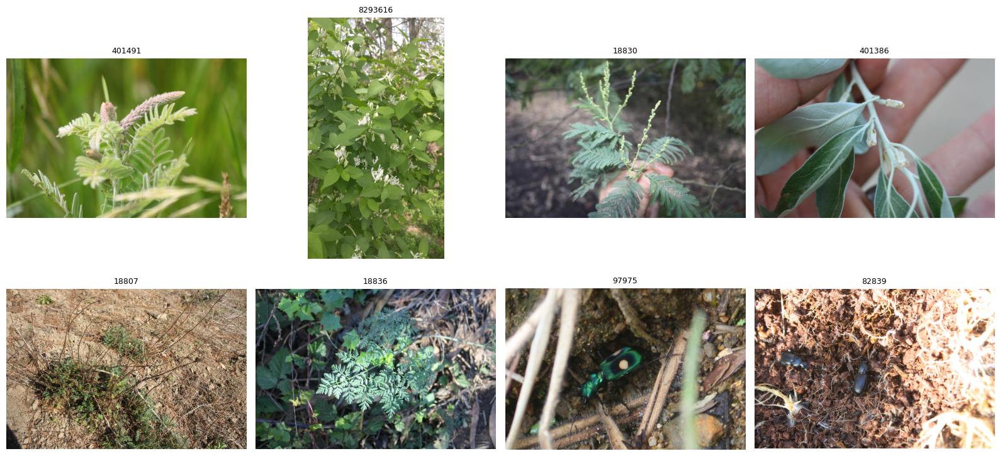

In [7]:
import collections
kinds = collections.Counter()
strange = []
for rec in exam:
    t = raw[rec["photo_id"]].replace("```json", "").replace("```", "").strip()
    if t == "[]":
        kinds["модель ответила [] (бабочек нет)"] += 1
    elif "bbox_2d" in t:
        kinds["есть bbox_2d"] += 1
    else:
        kinds["другой ответ"] += 1
        strange.append((rec["photo_id"], t[:200]))
print(kinds)
for pid, t in strange[:10]:
    print(pid, "|", t)

empty = [rec["photo_id"] for rec in exam if not result[rec["photo_id"]]]
random.seed(1)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, pid in zip(axes.flat, random.sample(empty, 8)):
    ax.imshow(Image.open(f"exam_images/{pid}.jpg").convert("RGB"))
    ax.set_title(str(pid), fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

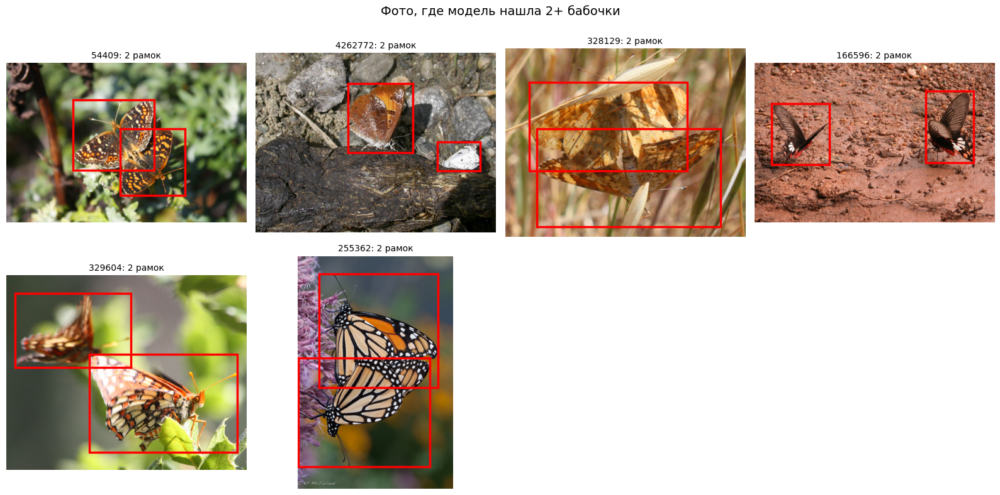

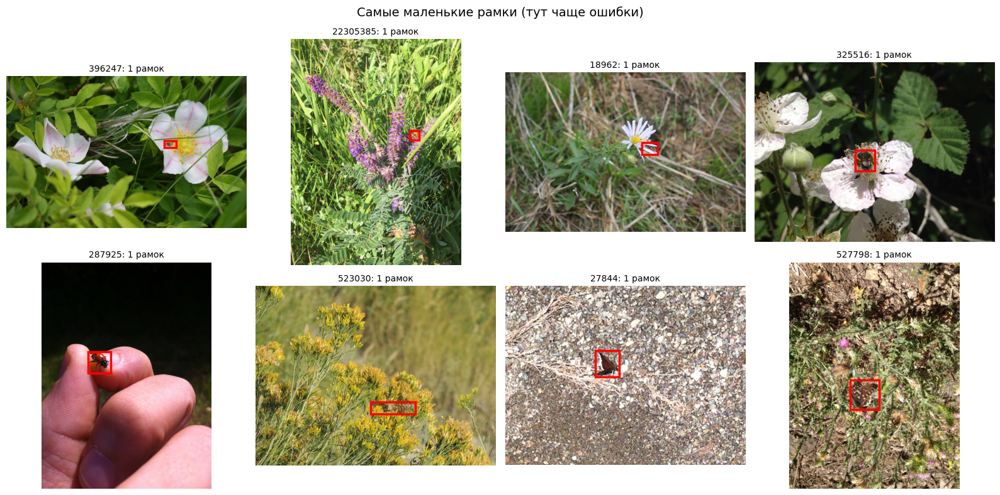

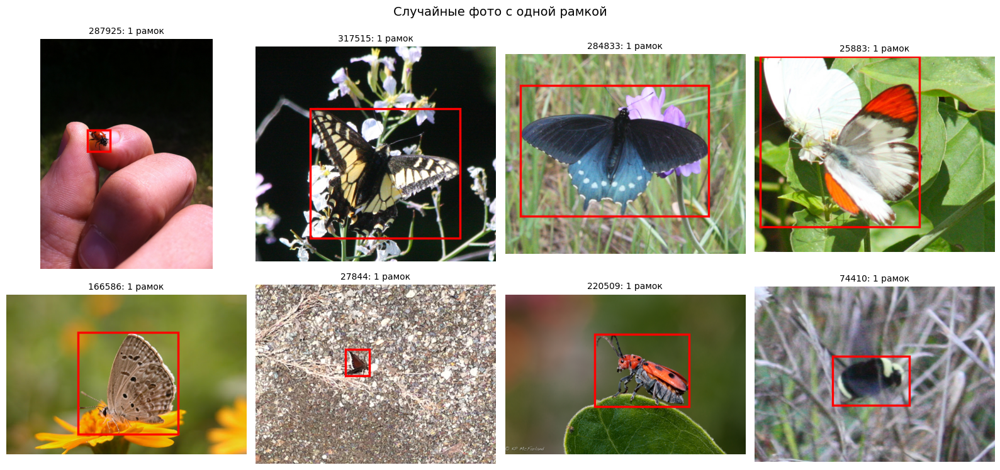

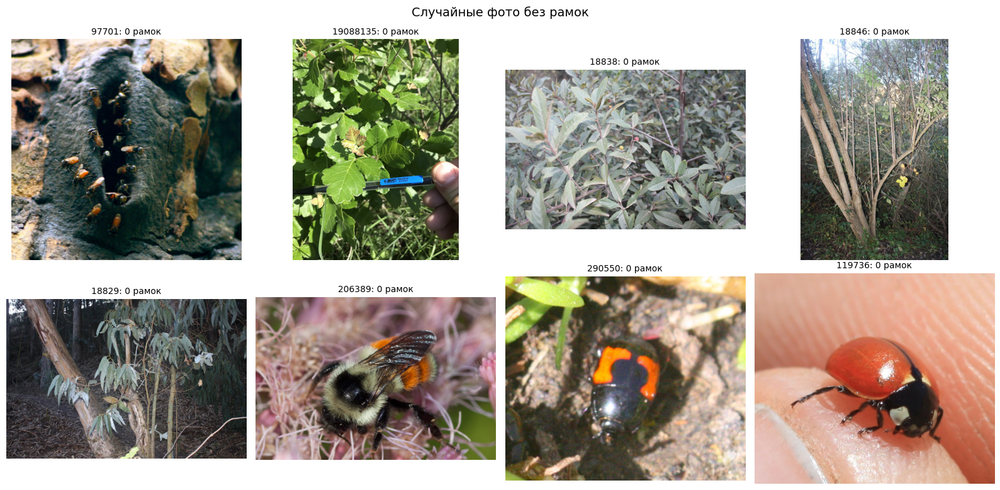

In [12]:
import random, matplotlib.pyplot as plt, matplotlib.patches as patches

rows = {r["photo_id"]: r["boxes"] for r in map(json.loads, open("exam_predictions.jsonl"))}

def show(ids, title):
    ids = list(ids)
    cols = 4
    rws = (len(ids) + cols - 1) // cols
    fig, axes = plt.subplots(rws, cols, figsize=(16, 4 * rws))
    for ax in axes.flat:
        ax.axis("off")
    for ax, pid in zip(axes.flat, ids):
        img = Image.open(f"exam_images/{pid}.jpg").convert("RGB")
        W, H = img.size
        ax.imshow(img)
        for b in rows[pid]:
            ax.add_patch(patches.Rectangle((b["left"] * W, b["top"] * H), b["width"] * W, b["height"] * H,
                                           fill=False, color="red", linewidth=2.5))
        ax.set_title(f"{pid}: {len(rows[pid])} рамок", fontsize=10)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

two = [pid for pid, b in rows.items() if len(b) >= 2]
show(two, "Фото, где модель нашла 2+ бабочки")

small = sorted([pid for pid, b in rows.items() if b], key=lambda pid: min(x["width"] * x["height"] for x in rows[pid]))[:8]
show(small, "Самые маленькие рамки (тут чаще ошибки)")

random.seed(2)
one = random.sample([pid for pid, b in rows.items() if len(b) == 1], 8)
show(one, "Случайные фото с одной рамкой")

empty = random.sample([pid for pid, b in rows.items() if not b], 8)
show(empty, "Случайные фото без рамок")

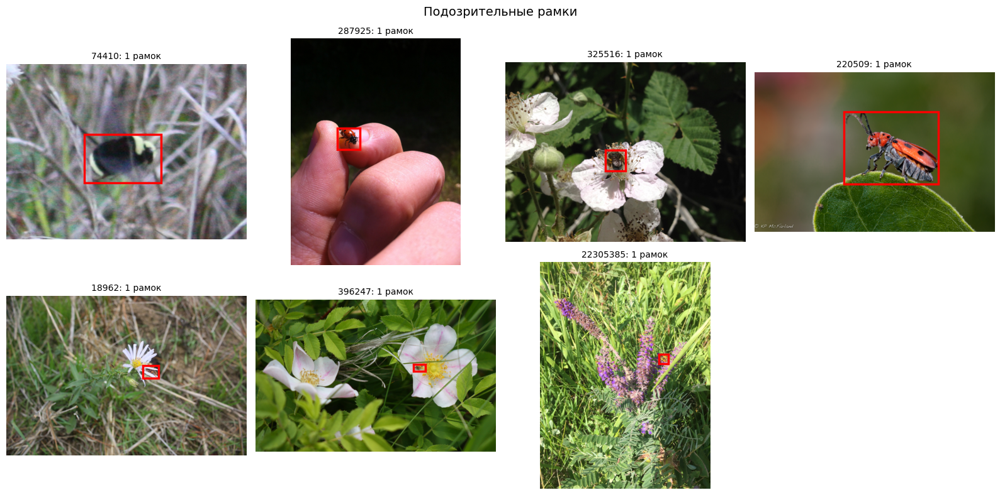

In [13]:
show([74410, 287925, 325516, 220509, 18962, 396247, 22305385], "Подозрительные рамки")

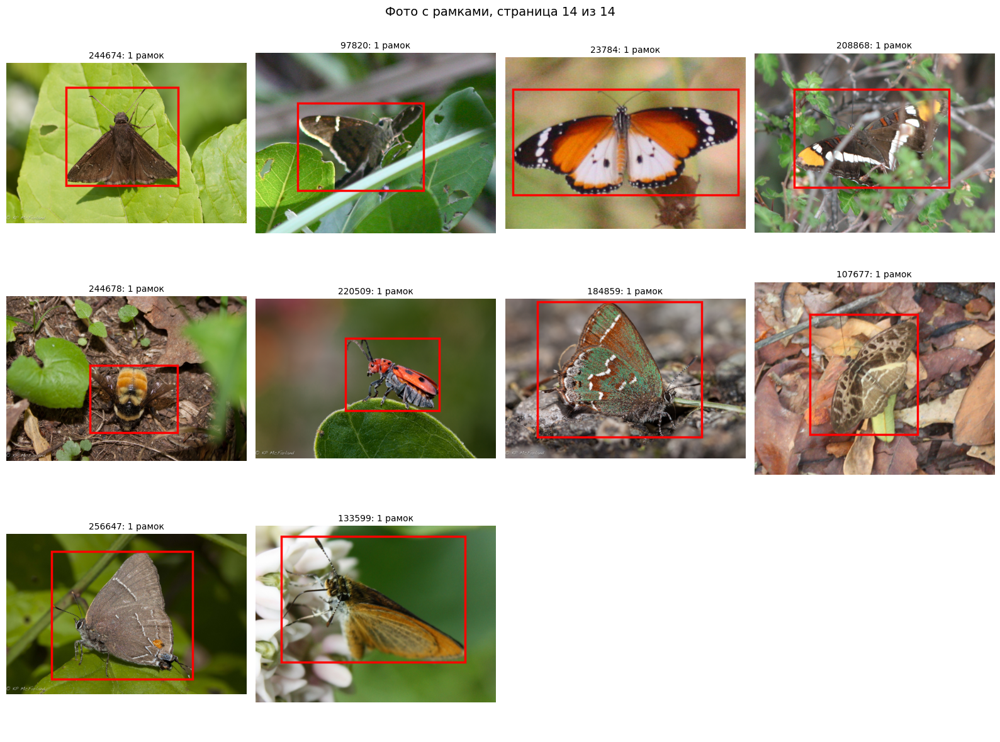

In [30]:
with_boxes = [pid for pid, b in rows.items() if b]
page = 13 
show(with_boxes[page * 16:(page + 1) * 16], f"Фото с рамками, страница {page + 1} из {len(with_boxes) // 16 + 1}")

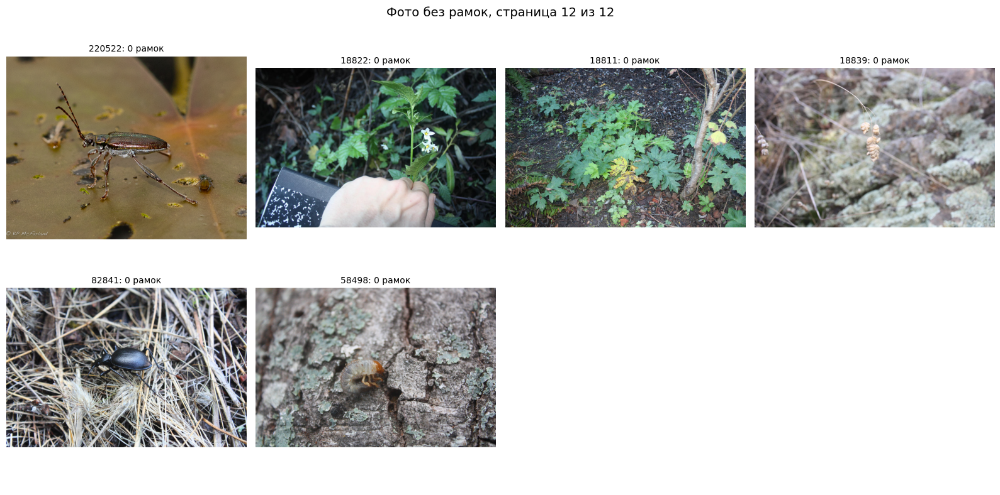

In [42]:
no_boxes = [pid for pid, b in rows.items() if not b]
page = 11    
show(no_boxes[page * 16:(page + 1) * 16], f"Фото без рамок, страница {page + 1} из {len(no_boxes) // 16 + 1}")